# Evaluacion final

Carlos Zambrano Figueroa | Grupo 11

Se evalua LR_base fijada antes de abrir la reserva: C=1, balanced, 18 predictores y preprocesamiento aprendido solo en desarrollo. Este notebook verifica las predicciones finales guardadas; no entrena, no selecciona candidatos y no vuelve a inferir sobre la reserva. La meta se conserva en F1 macro >= 0,60.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.final_evaluation import verify, render, RESULT
print(verify())
report = json.loads(RESULT.read_text())
render(report)

{'verified': True, 'test_rows': 885, 'model_refit': False}


In [2]:
baseline = json.loads((ROOT / 'results/metrics/baseline_results.json').read_text())['summary']['LR_base']
display(pd.DataFrame({'Validacion media 5 folds': [baseline['val_f1_macro'], baseline['val_accuracy'], baseline['val_recall20']], 'Prueba final 885 casos': [report['metrics']['f1_macro'], report['metrics']['accuracy'], report['metrics']['recall20']]}, index=['F1 macro', 'Accuracy', 'Cobertura 20%']))
print('Meta F1 >= 0.60 alcanzada:', report['target_met'])

,Validacion media 5 folds,Prueba final 885 casos
F1 macro,0.515839,0.493665
Accuracy,0.549584,0.528814
Cobertura 20%,0.397527,0.401408


Meta F1 >= 0.60 alcanzada: False


## Clases y errores

La matriz usa filas reales y columnas predichas. Enrolled no es un resultado definitivo de graduacion. La cobertura del ranking y el recall de clase Dropout son metricas distintas.

,precision,recall,f1-score,support
Dropout,0.552124,0.503521,0.526703,284.000000
Enrolled,0.277778,0.408805,0.330789,159.000000
Graduate,0.663265,0.588235,0.623501,442.000000
accuracy,0.528814,0.528814,0.528814,0.528814
macro avg,0.497722,0.500187,0.493665,885.000000
weighted avg,0.558342,0.528814,0.539849,885.000000


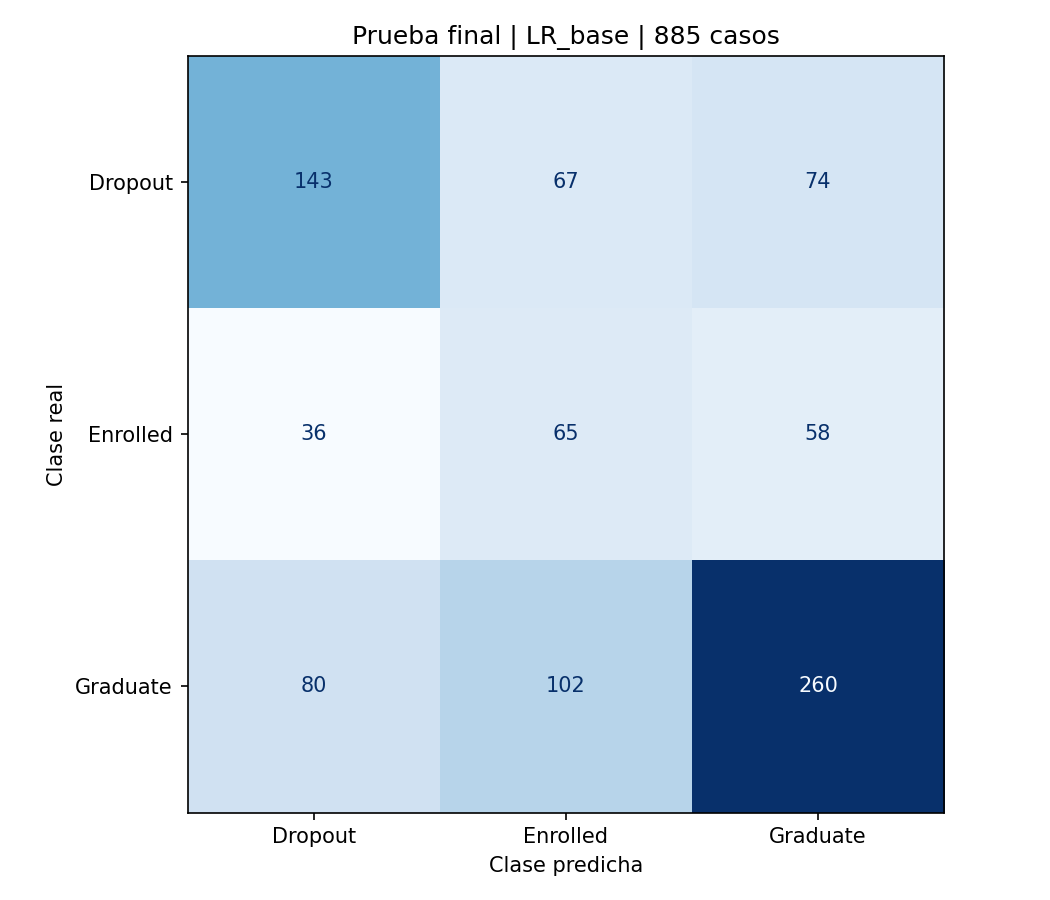

selected                    177.0
dropout_total               284.0
dropout_detected            114.0
dropout_missed              170.0
selected_other               63.0
random_expected_coverage      0.2
random_expected_detected     56.8
Name: Conteos y referencia aleatoria, dtype: float64

In [3]:
display(pd.DataFrame(report['class_report']).T)
display(Image(filename=str(ROOT / 'results/figures/final_test_confusion.png')))
display(pd.Series(report['ranking'], name='Conteos y referencia aleatoria'))

## Interpretacion

El resultado final no alcanza F1 de 0,60. No se modifican variables, parametros ni umbrales para mejorar esta prueba. La cobertura debe interpretarse junto con los abandonos que quedan fuera y los casos seleccionados sin abandono registrado. La referencia aleatoria es una esperanza matematica, no una prueba causal.

La auditoria por subgrupos y los escenarios de robustez se realizaron en desarrollo; no se presentan como mediciones de esta reserva. La prueba final no valida uso institucional en Ecuador ni la eficacia de una intervencion. La reserva ya fue utilizada y no se reutilizara para elegir modelos.

Los resultados y el informe se derivan del mismo archivo de predicciones, con verificacion de particiones y huellas del modelo.